**Code**

**Step 1: Import Libraries**

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

**Step 2: Load Data and Checking Missing Values**

In [23]:
df = pd.read_csv("./diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [24]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

**Step 3: Replace invalid 0s with NaN**

In [25]:
cols_with_zeros = [
    'Glucose', 'BloodPressure',
    'SkinThickness', 'Insulin', 'BMI'
]

df[cols_with_zeros] = df[cols_with_zeros].replace(0, np.nan)

df.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

In [26]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


**Step 4: Exploratory Data Analysis (EDA)**

**Histogram of all features**

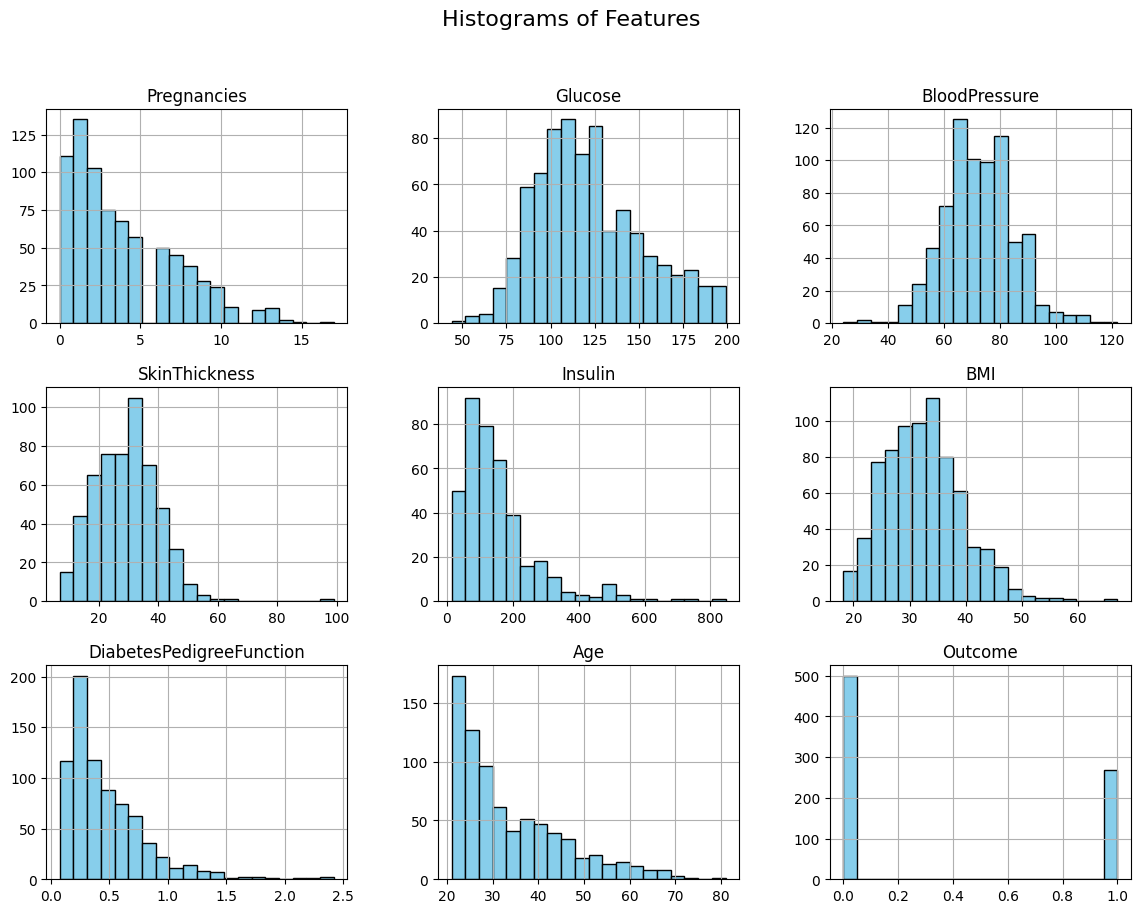

In [27]:
df.hist(bins=20, figsize=(14, 10), color='skyblue', edgecolor='black')
plt.suptitle("Histograms of Features", fontsize=16)
plt.show()

**Correlation heatmap**

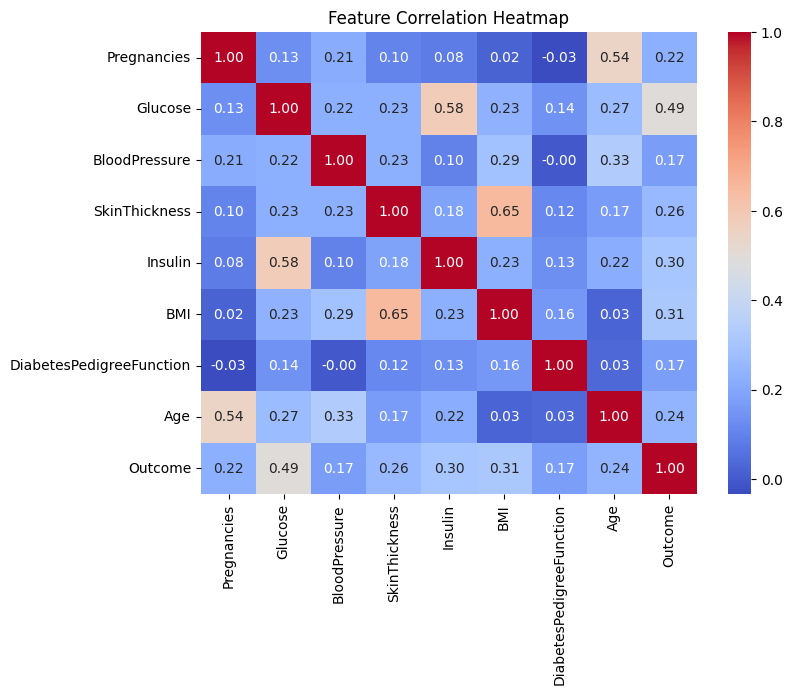

In [28]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

**Diabetes Outcome Count**

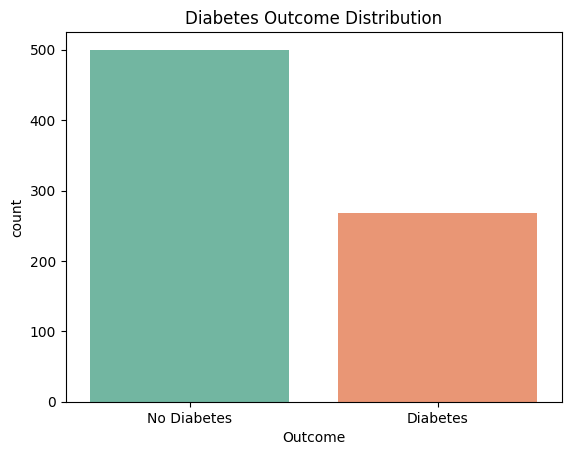

In [29]:
sns.countplot(data=df, x="Outcome", palette="Set2")
plt.title("Diabetes Outcome Distribution")
plt.xticks([0, 1], ["No Diabetes", "Diabetes"])
plt.show()

**Step 5: Split the Dataset**

In [30]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 614
Testing samples: 154


**Step 7: Define Models**

In [31]:
models = {
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(random_state=42))
    ])
}

**Step 8: Train and Evaluation without tuning**

In [32]:
untuned_results = {}

model = models["Decision Tree"]
model.fit(X_train, y_train)

pred = model.predict(X_test)
acc = accuracy_score(y_test, pred)

untuned_results["Decision Tree"] = {
    "model": model,
    "accuracy": acc,
    "prediction": pred
}

print("Untuned Decision Tree Accuracy:", round(acc, 4))

best_untuned_name = "Decision Tree"
best_untuned_model = model
best_untuned_accuracy = acc

Untuned Decision Tree Accuracy: 0.6818


**Step 9: Define Models parameter**

In [33]:
param_grids = {
    "Decision Tree": {
        "model__criterion": ["gini", "entropy", "log_loss"],
        "model__max_depth": [None, 3, 5, 7, 10],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 5, 10],
        "model__class_weight": [None, "balanced"]
    }
}

**Step 10: Train and Evaluation with tuning**

In [34]:
tuned_results = {}

search = GridSearchCV(
    models["Decision Tree"],
    param_grids["Decision Tree"],
    cv=5,
    scoring="f1",
    n_jobs=-1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_
pred = best_model.predict(X_test)
acc = accuracy_score(y_test, pred)

tuned_results["Decision Tree"] = {
    "model": best_model,
    "accuracy": acc,
    "prediction": pred
}

best_tuned_name = "Decision Tree"
best_tuned_model = best_model
best_tuned_accuracy = acc

print("Best Parameters:", search.best_params_)
print("Tuned Decision Tree Accuracy:", round(acc, 4))
print("Tuned Decision Tree F1-score:",
      round(search.best_score_, 4))

Best Parameters: {'model__class_weight': 'balanced', 'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 5, 'model__min_samples_split': 2}
Tuned Decision Tree Accuracy: 0.6818
Tuned Decision Tree F1-score: 0.6656


**Step 11: Compare Accuracy**

           Model  Untuned Accuracy  Tuned Accuracy
0  Decision Tree          0.681818        0.681818


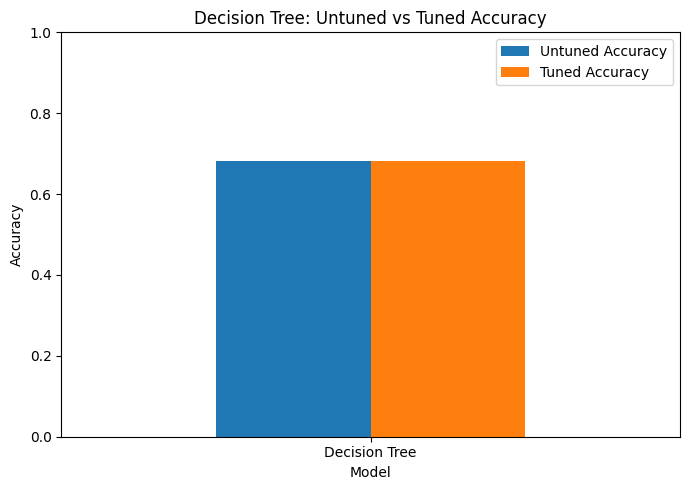

In [40]:
model_names = list(models.keys())

accuracy_df = pd.DataFrame({
    "Model": model_names,
    "Untuned Accuracy": [
        untuned_results[name]["accuracy"] for name in model_names
    ],
    "Tuned Accuracy": [
        tuned_results[name]["accuracy"] for name in model_names
    ]
})

print(accuracy_df)

accuracy_df.set_index("Model").plot(
    kind="bar", figsize=(7, 5), ylim=(0, 1)
)

plt.title("Decision Tree: Untuned vs Tuned Accuracy")
plt.ylabel("Accuracy")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Compare Accuracy into plot**

**Step 12: Confusion Matrix and Classification Report**

UNTUNED DECISION TREE


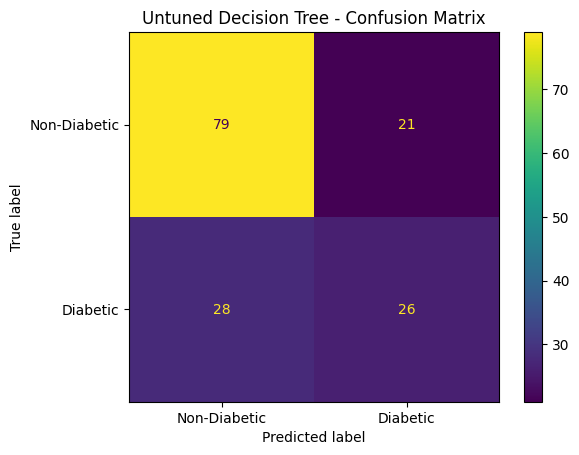

              precision    recall  f1-score   support

Non-Diabetic       0.74      0.79      0.76       100
    Diabetic       0.55      0.48      0.51        54

    accuracy                           0.68       154
   macro avg       0.65      0.64      0.64       154
weighted avg       0.67      0.68      0.68       154


TUNED DECISION TREE


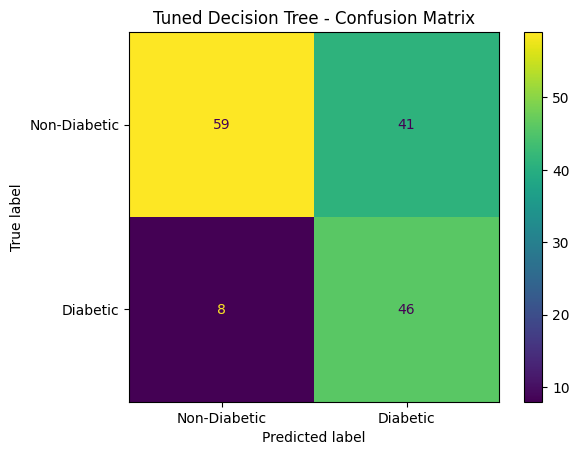

              precision    recall  f1-score   support

Non-Diabetic       0.88      0.59      0.71       100
    Diabetic       0.53      0.85      0.65        54

    accuracy                           0.68       154
   macro avg       0.70      0.72      0.68       154
weighted avg       0.76      0.68      0.69       154



In [41]:
print("UNTUNED DECISION TREE")
ConfusionMatrixDisplay.from_estimator(
    best_untuned_model, X_test, y_test,
    display_labels=["Non-Diabetic", "Diabetic"]
)
plt.title("Untuned Decision Tree - Confusion Matrix")
plt.show()

print(classification_report(
    y_test,
    best_untuned_model.predict(X_test),
    target_names=["Non-Diabetic", "Diabetic"],
    zero_division=0
))

print("\nTUNED DECISION TREE")
ConfusionMatrixDisplay.from_estimator(
    best_tuned_model, X_test, y_test,
    display_labels=["Non-Diabetic", "Diabetic"]
)
plt.title("Tuned Decision Tree - Confusion Matrix")
plt.show()

print(classification_report(
    y_test,
    best_tuned_model.predict(X_test),
    target_names=["Non-Diabetic", "Diabetic"],
    zero_division=0
))

**Feature Importance**

                    Feature  Importance
1                   Glucose    0.619688
5                       BMI    0.222701
7                       Age    0.157611
0               Pregnancies    0.000000
3             SkinThickness    0.000000
2             BloodPressure    0.000000
4                   Insulin    0.000000
6  DiabetesPedigreeFunction    0.000000


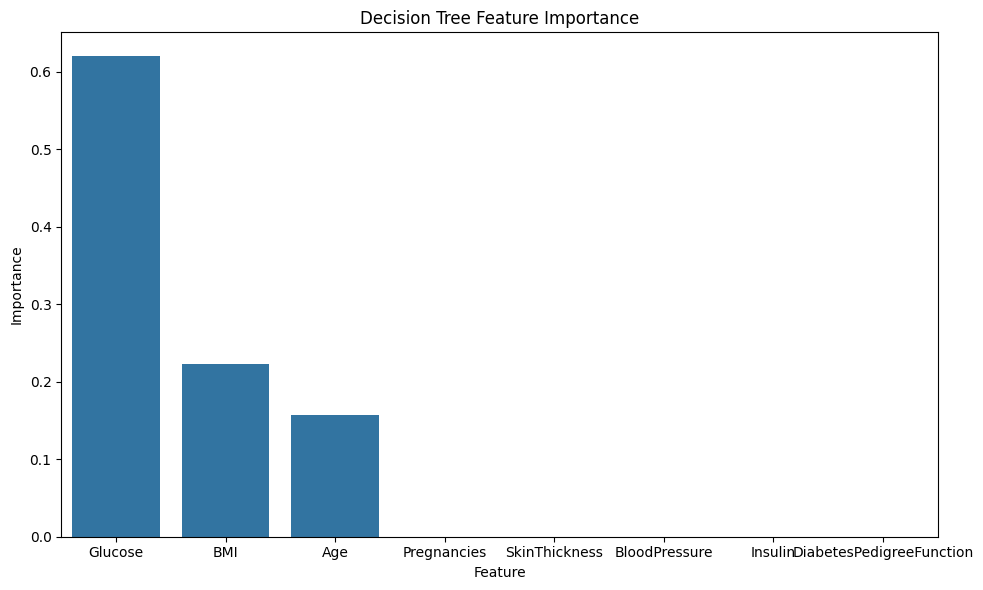

In [42]:
tree_model = best_tuned_model.named_steps["model"]

importances = tree_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print(importance_df)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x="Feature", y="Importance")
plt.title("Decision Tree Feature Importance")
plt.tight_layout()
plt.show()

In [43]:
sample = X_test.iloc[:10]
true_vals = y_test.loc[sample.index]

pred_untuned = best_untuned_model.predict(sample)
pred_tuned = best_tuned_model.predict(sample)

comparison_df = pd.DataFrame({
    "Actual Outcome": true_vals.values,
    "Untuned Decision Tree": pred_untuned,
    "Tuned Decision Tree": pred_tuned
})

comparison_df.replace(
    {0: "Non-Diabetic", 1: "Diabetic"},
    inplace=True
)

print("Test Set Prediction Comparison:")
print(comparison_df)

Test Set Prediction Comparison:
  Actual Outcome Untuned Decision Tree Tuned Decision Tree
0   Non-Diabetic              Diabetic            Diabetic
1   Non-Diabetic          Non-Diabetic            Diabetic
2   Non-Diabetic          Non-Diabetic        Non-Diabetic
3       Diabetic              Diabetic            Diabetic
4   Non-Diabetic              Diabetic        Non-Diabetic
5   Non-Diabetic          Non-Diabetic            Diabetic
6       Diabetic          Non-Diabetic            Diabetic
7       Diabetic              Diabetic            Diabetic
8   Non-Diabetic          Non-Diabetic        Non-Diabetic
9   Non-Diabetic              Diabetic            Diabetic


**Decision Tree visualization**

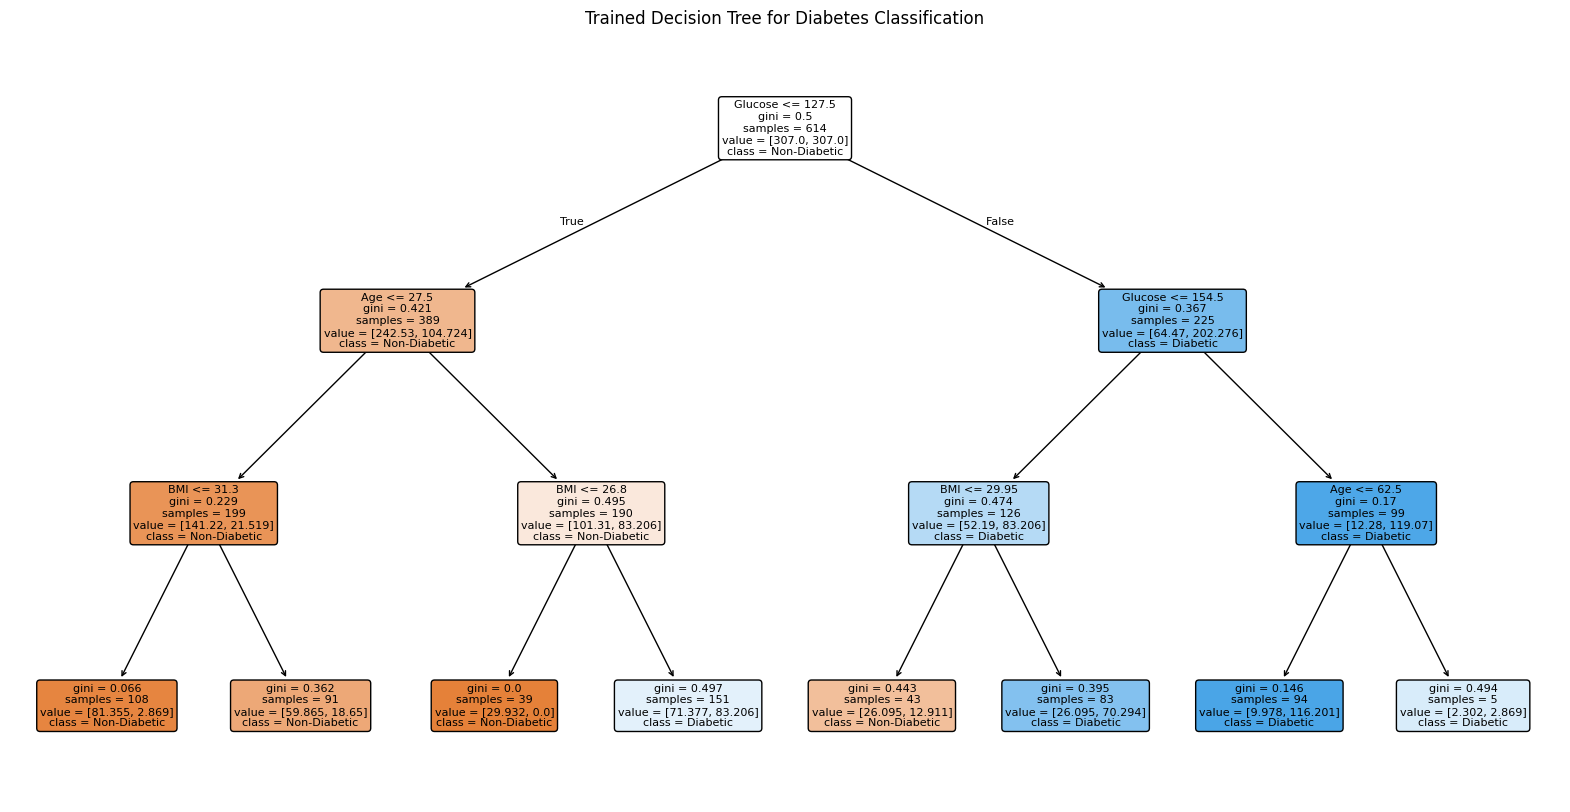

In [44]:
plt.figure(figsize=(20, 10))

plot_tree(
    best_tuned_model.named_steps["model"],
    feature_names=X.columns,
    class_names=["Non-Diabetic", "Diabetic"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Trained Decision Tree for Diabetes Classification")
plt.show()

**Step 13: Prediction**